Find god taksonomi - https://www.census.gov/naics/?input=71&chart=2017 ? foursquare?



In [1]:
from datetime import datetime, timedelta, date
import math
from pathlib import Path

import duckdb
import contextily as cx
import geopandas as gpd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import networkx as nx
import numpy as np
import orjson
import pandas as pd
import polars as pl
import seaborn as sns
import shapely
import statsmodels.formula.api as smf
from tqdm import tqdm

from wpp import db
from wpp.segregation import data
from wpp.utils import project_root

In [2]:
# config
sns.set_theme(style="ticks")
pl.Config.set_engine_affinity("streaming")

root = project_root()
db_path = root / "wpp.duckdb"
con = db.connect(db_path)

In [81]:
query = """
    WITH v AS (
        SELECT ID_STORE, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
        FROM visits
        GROUP BY ID_STORE
    )
    SELECT p.*, v.TOTAL_VISITORS
    FROM pois p
    JOIN v ON p.ID_STORE = v.ID_STORE
    WHERE CBSAFP = '35620'
"""
pois_dim = con.sql(query).pl().with_columns(
    pl.len().over("TOP_CATEGORY").alias("NUM_CATEGORY_POIS")
)
top_categories = set(pois_dim.group_by("TOP_CATEGORY").len().top_k(6, by="len")["TOP_CATEGORY"])
pois_dim = pois_dim.with_columns(
    pl.when(pl.col("TOP_CATEGORY").is_in(top_categories))
        .then(pl.col("TOP_CATEGORY"))
        .otherwise(pl.lit("Other"))
        .alias("TOP_CATEGORY_K")
)
pois_dim.head()

ID_STORE,POI_GEOID,CBSAFP,PERSISTENT_ID,BRAND,LOCATION_NAME,STREET_ADDRESS,CITY,REGION,ISO_COUNTRY_CODE,NAICS_CODE,TOP_CATEGORY,SUB_CATEGORY,OPEN_DATE,CLOSE_DATE,LONGITUDE,LATITUDE,GEOM,CELL_ID,TOTAL_VISITORS,NUM_CATEGORY_POIS,TOP_CATEGORY_K
str,str,str,str,str,str,str,str,str,str,str,str,str,date,date,f64,f64,ext[geoarrow.wkb],i64,"decimal[38,0]",u32,str
"""825678""","""361032009011""","""35620""","""A1_RL""","""Ralph Lauren""","""Ralph Lauren Corporation""","""57 Main Street""","""East Hampton""","""NY""","""US""","""448110""","""Clothing Stores ""","""Men's Clothing Stores """,1970-01-01,2038-01-01,-72.18681,40.962933,"b""\x01\x01\x00\x00\x00\x0c\xa5@\xb0\xf4\x0bR\xc0\xc7\x1d%eA{D@""",303343,5827,10637,"""Other"""
"""8265182""","""340130091002""","""35620""","""A1_NAICS-445310""","""Beer, Wine, and Liquor Stores""","""Beer, Wine, and Liquor Stores""","""152 Bloomfield Ave""","""Newark""","""NJ""","""US""","""445310""","""Beer, Wine, and Liquor Stores ""","""Beer, Wine, and Liquor Stores """,1970-01-01,2038-01-01,-74.175507,40.75872,"b""\x01\x01\x00\x00\x00\xdc\xce\x08\x80;\x8bR\xc0ng\x04\xc0\x1daD@""",310320,45207,2762,"""Other"""
"""8265296""","""340297158002""","""35620""","""A1_NAICS-453998""","""All Other Miscellaneous Store …","""Edmegastore""","""204 Hadassah Ln""","""Lakewood""","""NJ""","""US""","""453998""","""Other Miscellaneous Store Reta…","""All Other Miscellaneous Store …",1970-01-01,2038-01-01,-74.203217,40.076511,"b""\x01\x01\x00\x00\x00G\xc02\x80\x01\x8dR\xc0\xb6b$\x20\xcb\x09D@""",332799,9915,11260,"""Other Miscellaneous Store Reta…"
"""8265461""","""340030222001""","""35620""","""A1_NAICS-445299""","""All Other Specialty Food Store…","""All Other Specialty Food Store…","""410 Grove St""","""Glen Rock""","""NJ""","""US""","""445299""","""Specialty Food Stores ""","""All Other Specialty Food Store…",1970-01-01,2038-01-01,-74.111237,40.967159,"b""\x01\x01\x00\x00\x00\x91\xc7\x1d\x80\x1e\x87R\xc0\xd9\xc2=\xe0\xcb{D@""",303296,7539,3213,"""Other"""
"""8265641""","""340350509022""","""35620""","""A1_NAICS-448120""","""Women's Clothing Stores""","""Women's Clothing Stores""","""566 Morningside Dr""","""Bridgewater""","""NJ""","""US""","""448120""","""Clothing Stores ""","""Women's Clothing Stores """,1970-01-01,2038-01-01,-74.588959,40.58992,"b""\x01\x01\x00\x00\x00v\xcc\xd4\x7f\xb1\xa5R\xc0\xcf\xa0\xa1\x7f\x82KD@""",315930,108,10637,"""Other"""


We can use different definitions. For now, we use an adapted POI segregation from [Moro et al.](https://www.nature.com/articles/s41467-021-24899-8)

> To measure the income segregation of each place $\alpha$ in the city, we compute the proportion of total time spent at that place $\alpha$ by each income quartile $q$, $\tau _{q, \alpha}$, defining separate quartiles for each city. We define full integration of a place as $\tau _{q, \alpha} = \frac{1}{4}$ for each $q$, that is, the total time spent at venue $\alpha$ is split evenly across our four income quartiles. We then define the income segregation for each place $\alpha$, $S_\alpha$, as any deviation from our idealized measure of integration:
> $$S_{\alpha} = \frac{2}{3}\sum_{q=1}^{4}\left|\tau_{q\alpha} - \frac{1}{4}\right|$$

This definition generalizes to any number of groups as

$$
S_{\alpha}^{\{n\}} = \frac{n}{2n - 2}\sum_{q=1}^{n}\left|\tau_{q\alpha} - \frac{1}{n}\right|
$$

In [82]:
query = """
    WITH bg AS (
        SELECT
            GEOID, CBSAFP, MEDIAN_HH_INCOME,
            NTILE(4) OVER (PARTITION BY CBSAFP ORDER BY MEDIAN_HH_INCOME ASC) AS INCOME_GROUP
        FROM block_groups_cbsa
        WHERE CBSAFP = '35620'
          AND MEDIAN_HH_INCOME IS NOT NULL
    )
    SELECT v.ID_STORE, INCOME_GROUP, SUM(VISITOR_COUNTS) AS TOTAL_VISITORS
    FROM block_group_visits v
    JOIN bg ON v.HOME_GEOID = bg.GEOID
    GROUP BY v.ID_STORE, INCOME_GROUP
"""
poi_group_visits = con.sql(query).pl()
poi_visits = (
    poi_group_visits
        .sort("INCOME_GROUP")
        .pivot("INCOME_GROUP", index="ID_STORE", column_naming="combine")
        .fill_null(0)
        .with_columns(
            pl.sum_horizontal(pl.selectors.starts_with("TOTAL_VISITORS_")).alias("TOTAL_VISITORS")
        )
        .with_columns(
            (
                pl.selectors.starts_with("TOTAL_VISITORS_").cast(pl.Float64)
                / pl.col("TOTAL_VISITORS").replace({0: None})
            ).name.replace("TOTAL_VISITORS_", "TAU_")
        )
        .with_columns(
            (
                (2 / 3) * pl.sum_horizontal(
                    (pl.selectors.starts_with("TAU_") - (1/4)).abs()
                )
            ).alias("SEGREGATION")
        )
        .filter(pl.col("TOTAL_VISITORS") > 0)
)
poi_visits.head()

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

ID_STORE,TOTAL_VISITORS_1,TOTAL_VISITORS_2,TOTAL_VISITORS_3,TOTAL_VISITORS_4,TOTAL_VISITORS,TAU_1,TAU_2,TAU_3,TAU_4,SEGREGATION
str,"decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]","decimal[38,0]",f64,f64,f64,f64,f64
"""10732527""",222351,406172,566954,431804,1627281,0.13664,0.249602,0.348406,0.265353,0.151678
"""10840096""",35433,98210,128507,106224,368374,0.096188,0.266604,0.348849,0.288359,0.205083
"""10290811""",40311,22052,31369,21327,115059,0.350351,0.191658,0.272634,0.185357,0.16398
"""3791609""",15660,25322,17779,8165,66926,0.23399,0.378358,0.265652,0.122,0.192013
"""7621984""",7117,41020,53924,98216,200277,0.035536,0.204816,0.269247,0.490401,0.346197


In [83]:
pois = pois_dim.join(poi_visits, on="ID_STORE")

<Axes: xlabel='len', ylabel='TOP_CATEGORY'>

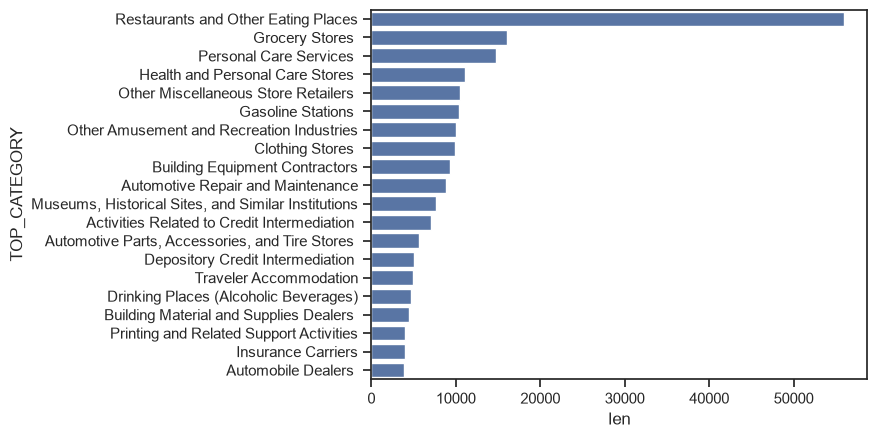

In [137]:
sns.barplot(
    pois.group_by("TOP_CATEGORY").len().sort("len", descending=True).top_k(20, by="len").to_pandas(),
    y="TOP_CATEGORY",
    x="len"
)

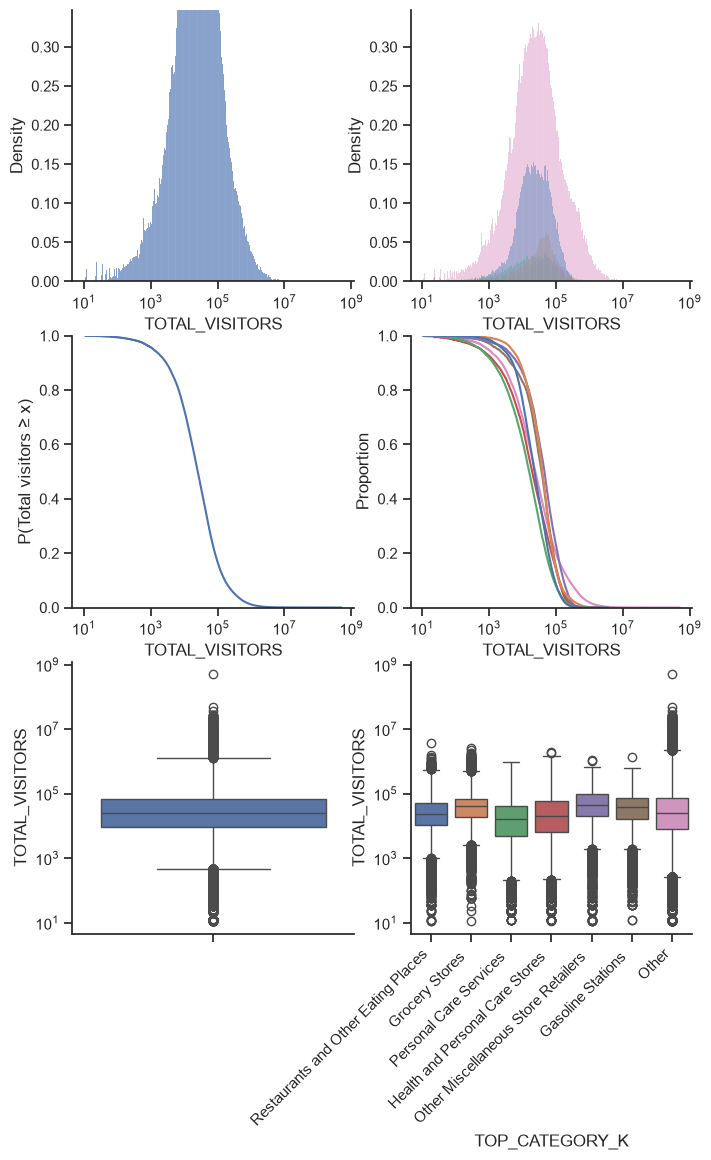

In [136]:
fig, axes = plt.subplots(3, 2, figsize=(8, 12))
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    stat="density",
    log_scale=True,
    ax=axes[0,0],
)
sns.histplot(
    pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    common_bins=True,
    common_norm=True,
    stat="density",
    log_scale=True,
    ax=axes[0,1],
    legend=False
)
axes[0,0].sharex(axes[0,1])
axes[0,0].sharey(axes[0,1])

sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    complementary=True,
    log_scale=True,
    ax=axes[1, 0],
)
sns.ecdfplot(
    data=pois_pd,
    x="TOTAL_VISITORS",
    hue="TOP_CATEGORY_K",
    complementary=True,
    log_scale=True,
    ax=axes[1, 1],
    legend=False,
)
axes[1,0].set_ylabel("P(Total visitors ≥ x)")
axes[1,0].sharex(axes[1,1])
axes[1,0].sharey(axes[1,1])

sns.boxplot(
    pois_pd,
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,0],
    legend=False
)

sns.boxplot(
    pois_pd,
    x="TOP_CATEGORY_K",
    y="TOTAL_VISITORS",
    log_scale=True,
    ax=axes[2,1],
    hue="TOP_CATEGORY_K",
    legend=False
)
axes[2,0].sharey(axes[2,1])
axes[2,1].tick_params("x", rotation=45, rotation_mode="xtick")

sns.despine()

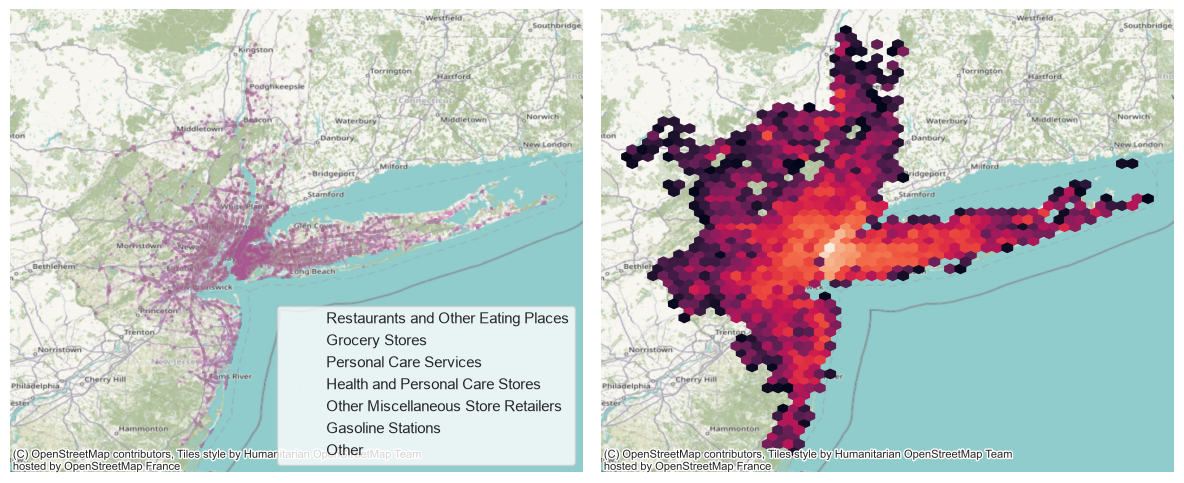

In [48]:
fig, axes = plt.subplots(1, 2, figsize=(12,5), sharex=True, sharey=True)

for (label,), g in pois.sort("NUM_CATEGORY_POIS", descending=True).group_by("TOP_CATEGORY_K", maintain_order=True):
    axes[0].scatter(g["LONGITUDE"], g["LATITUDE"], s=.1, alpha=.05, label=label)
axes[0].legend()
    
axes[1].hexbin(pois["LONGITUDE"], pois["LATITUDE"], mincnt=5, bins="log", gridsize=(50,30))

for ax in axes:
    cx.add_basemap(ax, zoom='auto', crs='EPSG:4326')
    ax.set_axis_off()
fig.tight_layout()

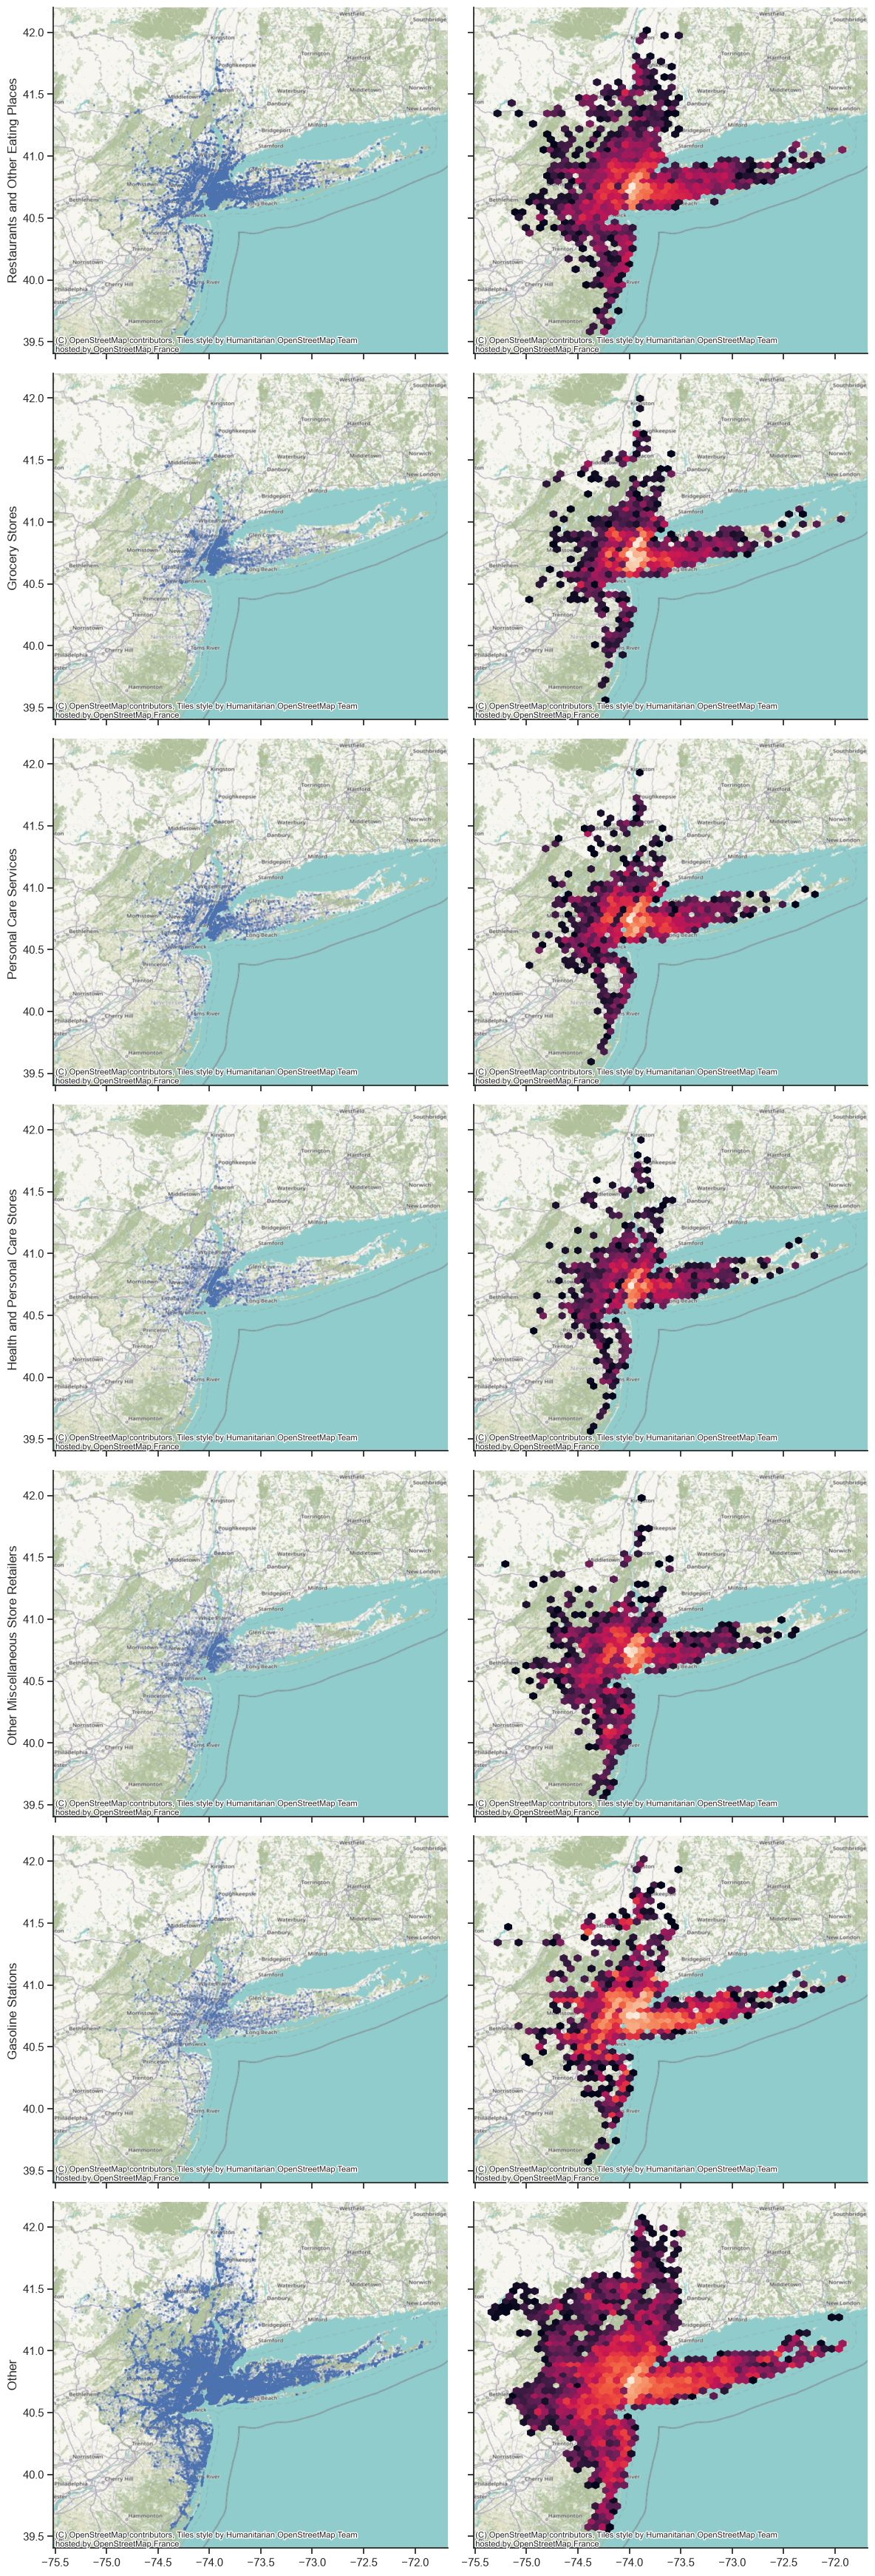

In [66]:
n_cat = len(top_categories) + 1
fig, axes = plt.subplots(n_cat, 2, figsize=(12,5*n_cat), sharex=True, sharey=True)

for i, ((label,), g) in enumerate(pois.sort("NUM_CATEGORY_POIS", descending=True).group_by("TOP_CATEGORY_K", maintain_order=True)):
    ax1 = axes[i, 0]
    ax2 = axes[i, 1]
    
    ax1.scatter(g["LONGITUDE"], g["LATITUDE"], s=1, alpha=.1)
    ax1.set_ylabel(label)
    
    ax2.hexbin(g["LONGITUDE"], g["LATITUDE"], mincnt=5, bins="log", gridsize=(50,30))

for ax in axes.flatten():
    cx.add_basemap(ax, zoom='auto', crs='EPSG:4326')

fig.tight_layout()

In [ ]:
fig, axes = plt.subplots(2, 2, sharex=True, sharey=True, figsize=(8,8))
axes = axes.flatten()
pois_pd = pois.with_columns(
    pl.col("TOTAL_VISITORS").cast(pl.Float64),
    pl.col("SEGREGATION").cast(pl.Float64),  # in case this is Decimal too
).sort("NUM_CATEGORY_POIS", descending=True).to_pandas()
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    bins=60,
    stat="density",
    ax=axes[0],
)
sns.histplot(
    pois_pd,
    x="SEGREGATION",
    weights="TOTAL_VISITORS",
    bins=60,
    stat="density",
    ax=axes[1]
)
sns.kdeplot(
    pois_pd,
    x="SEGREGATION",
    weights="TOTAL_VISITORS",
    # bins=60,
    # stat="density",
    hue="TOP_CATEGORY_K",
    common_norm=False,
    # common_bins=True,
    ax=axes[2],
)
sns.move_legend(
    axes[2], "lower center",
    bbox_to_anchor=(.5, 1), ncol=4, title=None, frameon=False,
)
sns.despine()